# Retail Sales & Profitability Analysis

##  Returns Analysis

### Project Overview

This notebook focuses on analysing returned orders within the US retail market.

The objective is to understand return patterns and identify areas that may require further investigation.

### Analysis Objectives

- Explore the Returns dataset.
- Check data quality.
- Connect Orders and Returns datasets.
- Calculate the overall return rate.
- Analyse returns across regions.
- Investigate return patterns by product category.
- Visualise the results.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
file_path = "sample_-_superstore.xls"
returns_df = pd.read_excel(
    file_path,
    sheet_name="Returns",
    engine="calamine"
)
returns_df.head()

,Order ID,Returned
0,US-2023-100762,Yes
1,US-2023-100867,Yes
2,US-2023-102652,Yes
3,US-2023-103373,Yes
4,US-2023-103744,Yes


In [3]:
returns_df.shape

(296, 2)

In [4]:
returns_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Order ID  296 non-null    str  
 1   Returned  296 non-null    str  
dtypes: str(2)
memory usage: 4.8 KB


In [5]:
returns_df.isna().sum()

Order ID    0
Returned    0
dtype: int64

In [6]:
returns_df.duplicated().sum()


np.int64(0)

In [7]:
returns_df["Order ID"].duplicated().sum()

np.int64(0)

In [8]:
returns_df["Returned"].value_counts(dropna=False)

Returned
Yes    296
Name: count, dtype: int64

In [9]:
# Load Orders dataset

orders_df = pd.read_excel(
    file_path,
    sheet_name="Orders",
    engine="calamine"
)
orders_us = orders_df[
    orders_df["Country/Region"] == "United States"
].copy()
orders_us.shape

(9994, 21)

In [10]:
returned_us = returns_df[
    returns_df["Order ID"].isin(orders_us["Order ID"])
].copy()
print("Total Returns Record:", len(returns_df))
print("US Returned Order", returned_us["Order ID"].nunique())
print("Total US Orders:", orders_us["Order ID"].nunique())

Total Returns Record: 296
US Returned Order 296
Total US Orders: 5009


In [11]:
# Calculate overall return rate

total_orders = orders_us["Order ID"].nunique()
returned_orders = returned_us["Order ID"].nunique()
return_rate = (returned_orders / total_orders) * 100

print(f"Total Orders: {total_orders:,}")
print(f"Returned Orders: {returned_orders:,}")
print(f"Return Rate: {return_rate:.2f}%")

Total Orders: 5,009
Returned Orders: 296
Return Rate: 5.91%


In [12]:
# Merge Orders and Returns

orders_returns = pd.merge(
    orders_us,
    returned_us,
    on="Order ID",
    how="left",
    validate="many_to_one"
)
orders_returns.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Returned
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,NaN
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,NaN
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,NaN
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,NaN
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,NaN


In [13]:
# Create return flag

orders_returns["Is_Returned_Order"] = (
    orders_returns["Returned"] == "Yes"
)
orders_returns["Is_Returned_Order"].value_counts()

Is_Returned_Order
False    9194
True      800
Name: count, dtype: int64

In [14]:
# Verify data integration

print("Original Order Rows:", len(orders_us))
print("Merge Dataset Rows:", len(orders_returns))
print("Unique Returned Orders:",
      orders_returns.loc[
          orders_returns["Is_Returned_Order"],
          "Order ID"
      ].nunique()
)

Original Order Rows: 9994
Merge Dataset Rows: 9994
Unique Returned Orders: 296


In [15]:
# Create unique orders by region

region_orders = (
    orders_returns.groupby(
        ["Region", "Order ID"],
        as_index=False
    ).agg(
        Is_Returned_Order=("Is_Returned_Order", "max")
    )
)
region_orders.head()

,Region,Order ID,Is_Returned_Order
0,Central,US-2023-100279,False
1,Central,US-2023-100678,False
2,Central,US-2023-100762,True
3,Central,US-2023-100853,False
4,Central,US-2023-101147,False


In [16]:
# Calculate return rate by region

regional_returns = region_orders.groupby("Region").agg(
    Total_Orders=("Order ID", "nunique"),
    Returned_Orders=("Is_Returned_Order", "sum")
).reset_index()
regional_returns["Return_Rate"] = (
    regional_returns["Returned_Orders"] /
    regional_returns["Total_Orders"]
) * 100
regional_returns = regional_returns.sort_values(
    "Return_Rate",
    ascending=False
)
regional_returns.round(2)

,Region,Total_Orders,Returned_Orders,Return_Rate
3,West,1611,189,11.73
0,Central,1175,39,3.32
1,East,1401,44,3.14
2,South,822,24,2.92


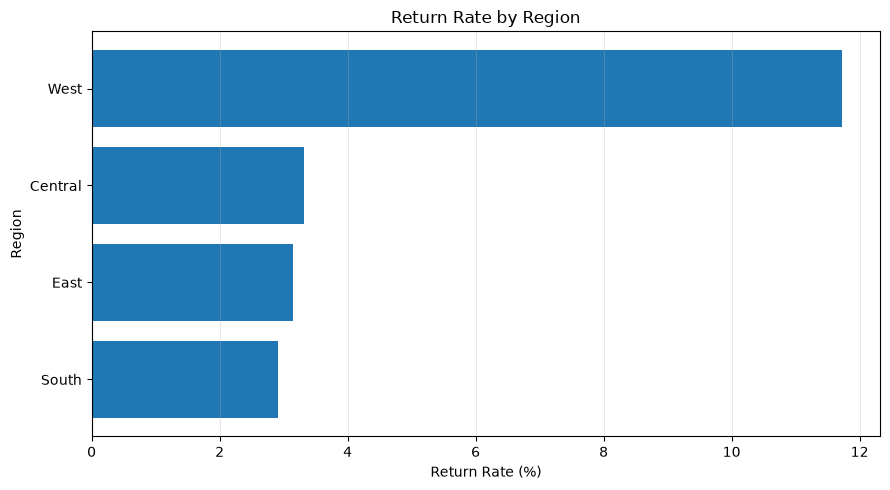

In [17]:
region_sorted = regional_returns.sort_values(
    "Return_Rate",
    ascending=True
)

plt.figure(figsize=(9, 5))
plt.barh(
    region_sorted["Region"],
    region_sorted["Return_Rate"]
)
plt.title("Return Rate by Region")
plt.xlabel("Return Rate (%)")
plt.ylabel("Region")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Create unique orders by category

category_orders = (
    orders_returns.groupby(
        ["Category", "Order ID"],
        as_index=False
    ).agg(
        Is_Returned_Order=("Is_Returned_Order", "max")
    )
)
category_orders.head()

,Category,Order ID,Is_Returned_Order
0,Furniture,US-2023-100090,False
1,Furniture,US-2023-100678,False
2,Furniture,US-2023-100706,False
3,Furniture,US-2023-100916,False
4,Furniture,US-2023-101462,False


In [19]:
# Calculate return rate by category

category_returns = category_orders.groupby("Category").agg(
    Total_Orders=("Order ID", "nunique"),
    Returned_Orders=("Is_Returned_Order", "sum")
).reset_index()

# Calculate return rate

category_returns["Return_Rate"] = (
    category_returns["Returned_Orders"] / 
    category_returns["Total_Orders"]
) * 100
category_returns= category_returns.sort_values(
    "Return_Rate",
    ascending=False
)
category_returns.round(2)

,Category,Total_Orders,Returned_Orders,Return_Rate
2,Technology,1544,123,7.97
0,Furniture,1764,136,7.71
1,Office Supplies,3742,234,6.25


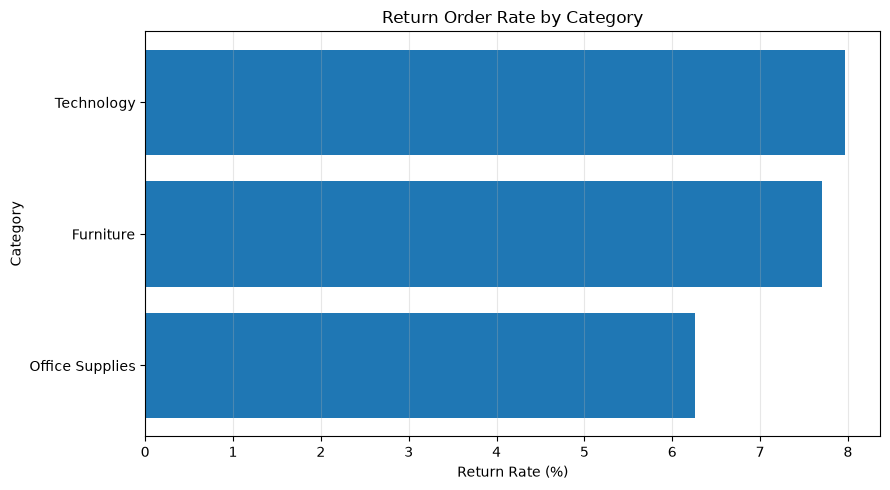

In [20]:
category_sorted = category_returns.sort_values(
    "Return_Rate",
    ascending=True
)
plt.figure(figsize=(9, 5))
plt.barh(
    category_sorted["Category"],
    category_sorted["Return_Rate"]
)
plt.title("Return Order Rate by Category")
plt.xlabel("Return Rate (%)")
plt.ylabel("Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
west_orders = orders_returns[
    orders_returns["Region"] == "West"
].copy()
west_orders.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Returned,Is_Returned_Order
11,12,US-2023-130813,2023-01-06,2023-01-08,Second Class,LS-17230,Lycoris Saunders,Consumer,United States,Los Angeles,...,OFF-PA-10002005,Office Supplies,Paper,Xerox 225,19.440,3,0.00,9.3312,NaN,False
21,22,US-2023-157147,2023-01-13,2023-01-18,Standard Class,BD-11605,Brian Dahlen,Consumer,United States,San Francisco,...,FUR-BO-10003034,Furniture,Bookcases,"O'Sullivan Elevations Bookcase, Cherry Finish",333.999,3,0.15,3.9294,NaN,False
23,24,US-2023-157147,2023-01-13,2023-01-18,Standard Class,BD-11605,Brian Dahlen,Consumer,United States,San Francisco,...,OFF-AR-10003514,Office Supplies,Art,4009 Highlighters by Sanford,19.900,5,0.00,6.5670,NaN,False
30,31,US-2023-157147,2023-01-13,2023-01-18,Standard Class,BD-11605,Brian Dahlen,Consumer,United States,San Francisco,...,OFF-ST-10000078,Office Supplies,Storage,Tennsco 6- and 18-Compartment Lockers,1325.850,5,0.00,238.6530,NaN,False
38,39,US-2023-123477,2023-01-18,2023-01-21,Second Class,DW-13195,David Wiener,Corporate,United States,Springfield,...,OFF-AP-10000692,Office Supplies,Appliances,Fellowes Mighty 8 Compact Surge Protector,64.864,4,0.20,6.4864,NaN,False


In [22]:
# Create unique orders by category in West region

west_category_orders = (
    west_orders.groupby(
        ["Category", "Order ID"],
        as_index=False
    ).agg(
        Is_Returned_Order=("Is_Returned_Order", "max")
    )
)
west_category_orders.head()

,Category,Order ID,Is_Returned_Order
0,Furniture,US-2023-100090,False
1,Furniture,US-2023-101462,False
2,Furniture,US-2023-101931,False
3,Furniture,US-2023-102295,False
4,Furniture,US-2023-102652,True


In [23]:
# Calculate return rate by category in West region

west_category_returns = west_category_orders.groupby(
    "Category"
).agg(
    Total_Orders=("Order ID", "nunique"),
    Returned_Orders=("Is_Returned_Order", "sum")
).reset_index()

west_category_returns["Return_Rate"] = (
    west_category_returns["Returned_Orders"] / 
    west_category_returns["Total_Orders"]
) * 100
west_category_returns = west_category_returns.sort_values(
    "Return_Rate",
    ascending=False
)
west_category_returns.round(2)

,Category,Total_Orders,Returned_Orders,Return_Rate
0,Furniture,595,88,14.79
2,Technology,490,68,13.88
1,Office Supplies,1169,149,12.75


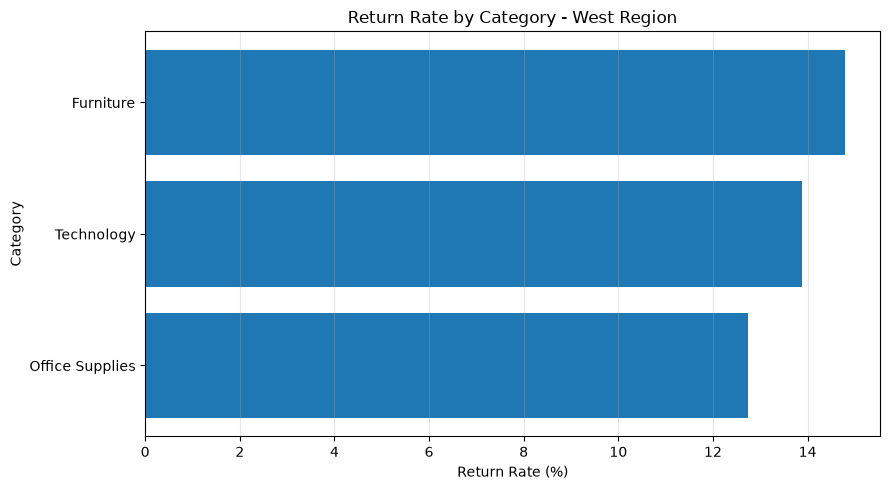

In [24]:
west_category_sorted = west_category_returns.sort_values(
    "Return_Rate",
    ascending=True
)
plt.figure(figsize=(9, 5))
plt.barh(
    west_category_sorted["Category"],
    west_category_sorted["Return_Rate"]
)
plt.title("Return Rate by Category - West Region")
plt.xlabel("Return Rate (%)")
plt.ylabel("Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# Create unique orders for time analysis

orders_by_id = (
    orders_returns.groupby(
        "Order ID",
        as_index=False
    ).agg(
        Order_Date=("Order Date", "min"),
        Is_Returned_Order=("Is_Returned_Order", "max")
    )
)
orders_by_id.head()

,Order ID,Order_Date,Is_Returned_Order
0,US-2023-100006,2023-09-07,False
1,US-2023-100090,2023-07-08,False
2,US-2023-100279,2023-03-10,False
3,US-2023-100293,2023-03-14,False
4,US-2023-100328,2023-01-28,False


In [26]:
# Extract year from Order Date

orders_by_id["Order_Date"] = pd.to_datetime(
    orders_by_id["Order_Date"]
)
orders_by_id["Order_Year"] = (
    orders_by_id["Order_Date"].dt.year
)
orders_by_id.head()

,Order ID,Order_Date,Is_Returned_Order,Order_Year
0,US-2023-100006,2023-09-07,False,2023
1,US-2023-100090,2023-07-08,False,2023
2,US-2023-100279,2023-03-10,False,2023
3,US-2023-100293,2023-03-14,False,2023
4,US-2023-100328,2023-01-28,False,2023


In [27]:
# Calculate Yearly Return Rate
yearly_returns = orders_by_id.groupby(
    "Order_Year"
).agg(
    Total_Orders=("Order ID", "nunique"),
    Returned_Orders=("Is_Returned_Order", "sum")
).reset_index()
yearly_returns["Return_Rate"] = (
    yearly_returns["Returned_Orders"] / 
    yearly_returns["Total_Orders"]
) * 100
yearly_returns.round(2)

,Order_Year,Total_Orders,Returned_Orders,Return_Rate
0,2023,969,53,5.47
1,2024,1038,61,5.88
2,2025,1315,77,5.86
3,2026,1687,105,6.22


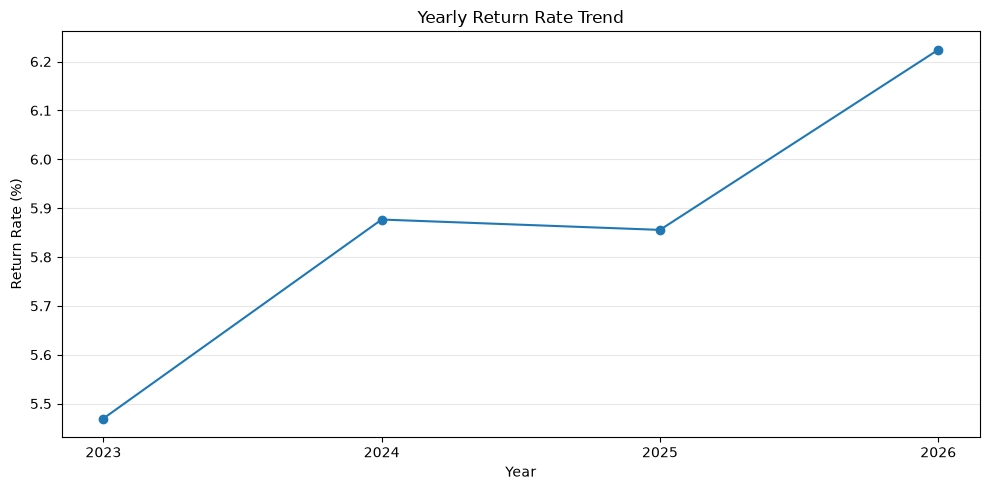

In [28]:
yearly_sorted = yearly_returns.sort_values(
    "Order_Year",
    ascending=True
)
plt.figure(figsize=(10, 5))
plt.plot(
    yearly_sorted["Order_Year"],
    yearly_sorted["Return_Rate"],
    marker="o",
    markersize=6
)
plt.title("Yearly Return Rate Trend")
plt.xlabel("Year")
plt.ylabel("Return Rate (%)")
plt.xticks(yearly_sorted["Order_Year"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# Calculate monthly return rate

monthly_returns = (
    orders_by_id.groupby(
        pd.Grouper(key="Order_Date", freq="MS")
    ).agg(
        Total_Orders=("Order ID", "nunique"),
        Returned_Orders=("Is_Returned_Order", "sum")
    ).reset_index()
)
monthly_returns["Return_Rate"] = (
    monthly_returns["Returned_Orders"] /
    monthly_returns["Total_Orders"]
) * 100
monthly_returns.head(12)

,Order_Date,Total_Orders,Returned_Orders,Return_Rate
0,2023-01-01,32,1,3.125000
1,2023-02-01,28,1,3.571429
2,2023-03-01,71,2,2.816901
3,2023-04-01,66,2,3.030303
4,2023-05-01,69,4,5.797101
5,2023-06-01,66,2,3.030303
6,2023-07-01,65,6,9.230769
7,2023-08-01,72,8,11.111111
8,2023-09-01,130,7,5.384615
9,2023-10-01,78,4,5.128205


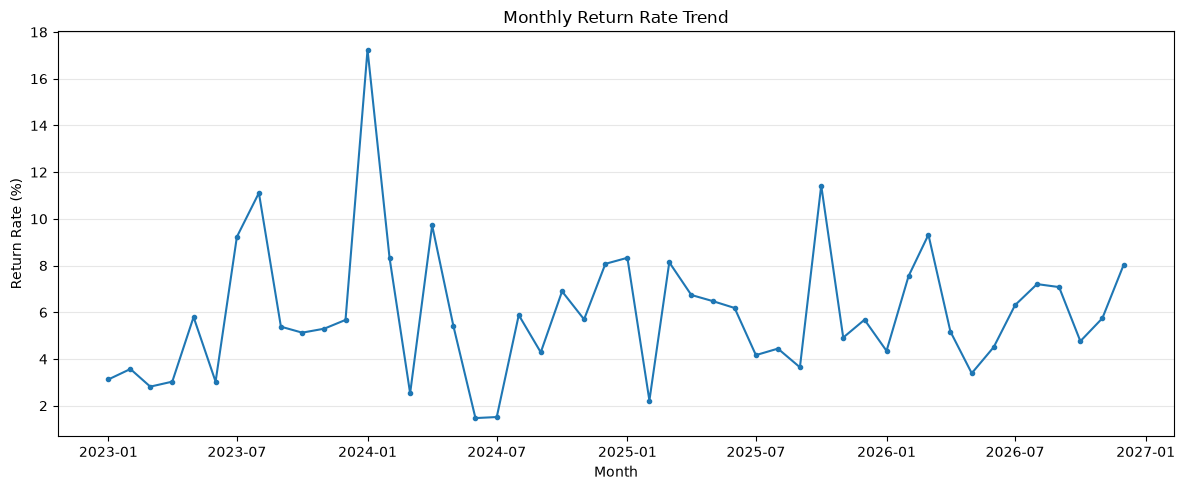

In [30]:
monthly_sorted = monthly_returns.sort_values(
    "Order_Date",
    ascending=True
)
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sorted["Order_Date"],
    monthly_sorted["Return_Rate"],
    marker="o",
    markersize=3
)
plt.title("Monthly Return Rate Trend")
plt.xlabel("Month")
plt.ylabel("Return Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Key Findings

- The overall order return rate is **5.91%**.
- The West region has the highest return rate (**11.73%**).
- Technology has the highest category-level return rate (**7.97%**).
- Within the West region, Furniture has the highest return rate (**14.79%**).
- The yearly return rate increased slightly from **5.47% in 2023** to **6.22% in 2026**.

These findings suggest that return patterns vary across regions and product categories, particularly in the West.

Further investigation is needed to understand the reasons behind these differences.